
# Lab 7: Fast Fourier Transform (FFT)

## Librerias

In [93]:
import warnings

import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from numpy.exceptions import ComplexWarning
from scipy import integrate
from scipy.fft import fft, fft2, fftfreq, fftshift, ifft2, ifftshift
from scipy.integrate import IntegrationWarning

warnings.filterwarnings('ignore', category=ComplexWarning)
warnings.filterwarnings('ignore', category=IntegrationWarning)

## **Example 1** : Chord - musical sound: Do mayor. Done in class.

![Do mayor](https://upload.wikimedia.org/wikipedia/commons/7/79/Major_chord_on_C.png)

Load the Nota_CM_piano.mp3 file from a Do mayor sound:




### 1. Do the FFT using scipy and Numpy rutines (see notebook)

In [2]:
signal, sr = librosa.load(r"C:\Users\PC\Downloads\Nota_CM_piano.mp3", sr=None)
print(f"sample rate: {sr} Hz")
print(f"signal shape: {signal.shape[0]} muestras")

sample rate: 44100 Hz
signal shape: 152064 muestras


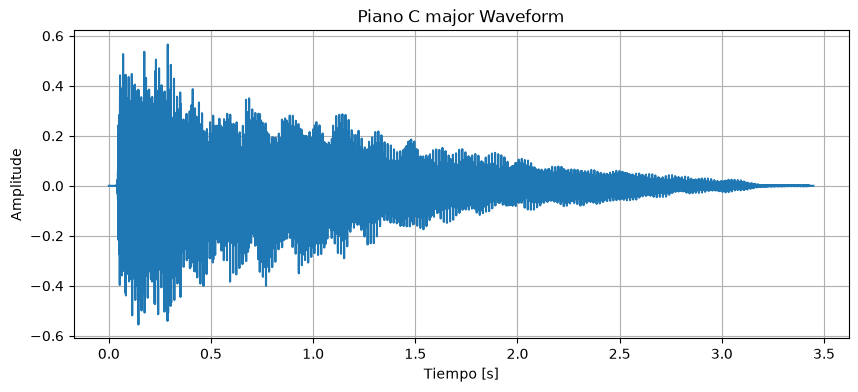

In [3]:
t = np.arange(len(signal)) / sr # tiempo transcurrido entre cada muestra
plt.figure(figsize=(10, 4))
plt.plot(t, signal)
plt.grid()
plt.title("Piano C major Waveform")
plt.xlabel("Tiempo [s]") 
plt.ylabel("Amplitude")
plt.show()

In [4]:
# Transformada de Fourier
N = signal.shape[0]
amplitud = fft(signal)
frecuencia = fftfreq(N, 1/sr)
# Frecuencias Positivas (Plus)
amplitud_real = (2/N)*np.abs(amplitud)  
filtro = frecuencia >=  0 
amplitud_real = amplitud_real[filtro]
frecuencia_plus = frecuencia[filtro]

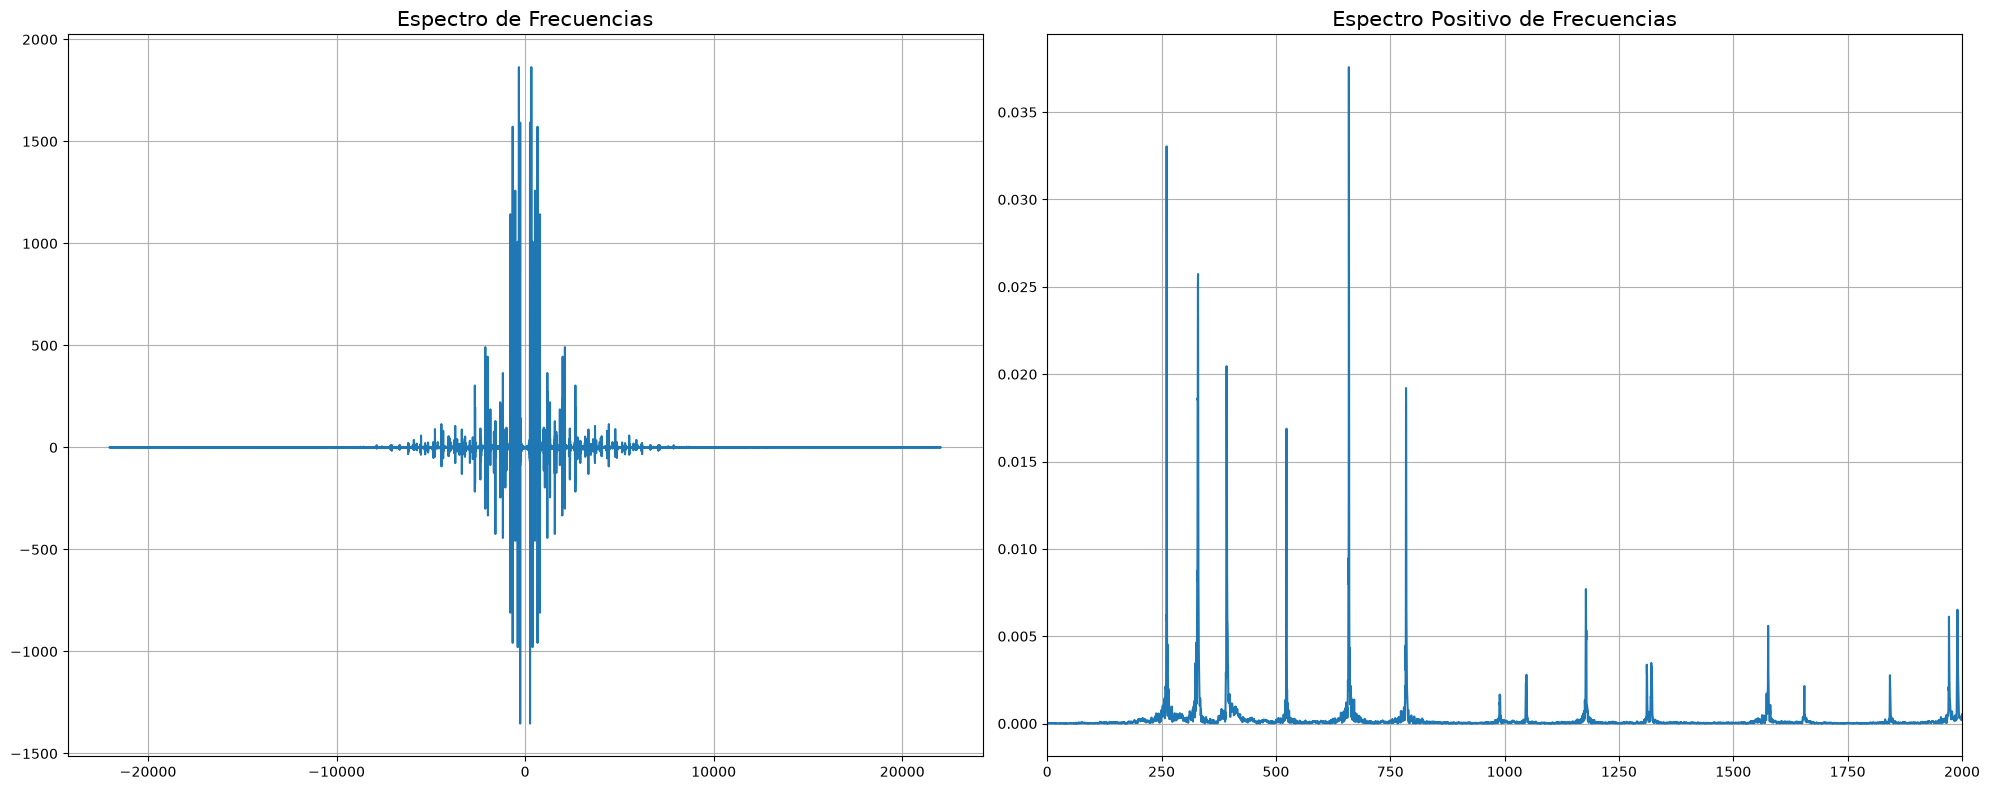

In [26]:
fig, ax  = plt.subplots(1,2, figsize=(20,8))

ax[0].set_title("Espectro de Frecuencias", fontsize = 15)
ax[0].plot(frecuencia, amplitud)
ax[0].grid(True)

ax[1].set_title("Espectro Positivo de Frecuencias", fontsize = 15)
ax[1].plot(frecuencia_plus, amplitud_real)
ax[1].grid(True)
ax[1].set_xlim(0,2000)

plt.tight_layout()
plt.show()
warnings.filterwarnings('ignore', category=ComplexWarning)

### 2. Used the rutine created in class `FT(x,y)`. Modify it and do the FT to the signal. Do you get the same results?

<span style="color:#7EED6D; font-size:20px">Codigo extraido de la sesion 2 fourier transform<span>

In [6]:
# Base Continua de la Fourier
def g(t,w):
    return 1./(2*np.pi)*np.exp(-1j*2*np.pi*w*t)

Nota: la señal no necesita interpolacion 

In [33]:
def FT(x,y):
    '''Integrar la Transformada de Fourier de f(t) en un rango de frecuencias w'''

    # Espectro de frecuencias
    w = np.linspace(0,2000,700) 

    df = []
    for i in range(len(w)):
        ARew = integrate.quad(lambda t, w_val=w[i]: np.interp(t, x, y) * g(t, w_val).real, x.min(), x.max())[0]
        AImw = integrate.quad(lambda t, w_val=w[i]: np.interp(t, x, y) * g(t, w_val).imag, x.min(), x.max())[0]
        AMP = np.sqrt(ARew**2 + AImw**2)
        ANG = np.arctan2(AImw, ARew)
        df.append([w[i], ARew, AImw, AMP, ANG])

    # DataFrame
    df = pd.DataFrame(df, columns=['w', 'ReTw', 'ImTw', 'AMP', 'ANG'])
    return df    

In [34]:
df = pd.DataFrame(FT(t, signal), columns=['w', 'ReTw', 'ImTw', 'AMP', 'ANG'])
df[:3]  

,w,ReTw,ImTw,AMP,ANG
0,0.000000,0.001055,0.000000,0.001055,0.000000
1,2.861230,-0.001656,0.000686,0.001792,2.749004
2,5.722461,0.000417,-0.000376,0.000561,-0.734589


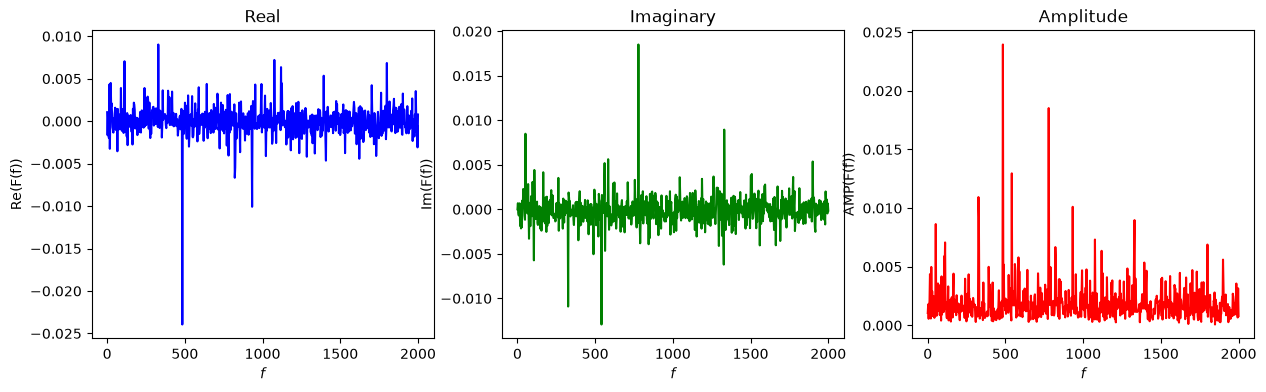

In [36]:
plt.figure(figsize=(15,4))
######## REAL ###########
plt.subplot(1,3,1)
plt.plot(df.w, df.ReTw,'b-')
plt.title('Real')
plt.xlabel('$f$')
plt.ylabel('Re(F(f))')
######### IMAG ##########
plt.subplot(1,3,2)
plt.plot(df.w, df.ImTw,'g-')
plt.title('Imaginary')
plt.xlabel('$f$')
plt.ylabel('Im(F(f))')
######### AMP ##########
plt.subplot(1,3,3)
plt.plot(df.w, df.AMP,'r-')
plt.title('Amplitude')
plt.xlabel('$f$')
plt.ylabel('AMP(F(f))')
plt.show()

Comparandolo con lo obtenido utilizando scipy es parecido se nota pero la razon por que se parece fue que lo hice para 700 frecuencias entre 0 y 2000 hz lo cual tuvo una duracion de 17 min y 10 sg, cuando lo hice para menos no estaba tan claro los picos y para 400 frecuencias algunos picos si se mostraban otros no. Lo que esta claro es que a mayor cantidad de frecuencias que se integren para el tiempo total de la nota más se acerca a lo obtenido con los metodos de scipy. La transformacion de fourier si devolvera los picos solo si se evalua f(t) para las frecuencias que conformen la señal por tanto si se saltan o se omiten no se obtendra ningún pico.

## **Exercise 1** : Do the FFT for an Imagen

Choose an Imagen





### 1. Do the FFT using scipy (see notebook)

In [41]:
def imagen(x, y):
    return np.cos(2 * np.pi * 0.1 * x) * np.cos(2 * np.pi * 0.2 * y) + 1

Se creo una imagen simple para luego cuando se haga la transformadora de fourier con FT modificado saber donde buscar

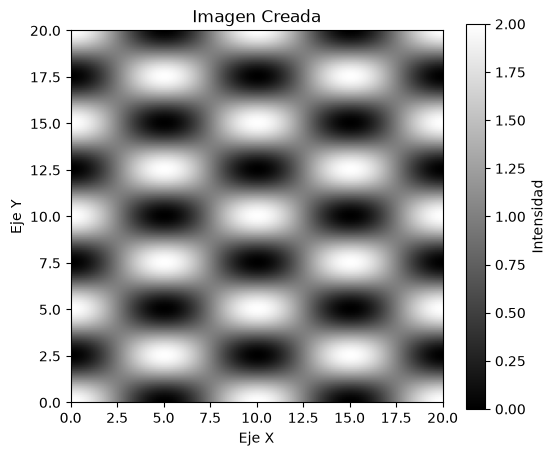

In [153]:
n_puntos = 200
x = np.linspace(0, 20, 200, endpoint=False)
y = np.linspace(0, 20, 200, endpoint=False)
X, Y = np.meshgrid(x, y)

Z = imagen(X, Y)

plt.figure(figsize=(6, 5))
plt.imshow(Z, extent=[0, 20, 0, 20], origin="lower", cmap="gray")
plt.colorbar(label="Intensidad")
plt.title("Imagen Creada")
plt.xlabel("Eje X")
plt.ylabel("Eje Y")
plt.show()


In [154]:
Z_fourier = fft2(Z)
Z_fourier_centrado = fftshift(Z_fourier)
amplitud_normalizada = np.abs(Z_fourier_centrado) / (200 * 200)
dx = x[1] - x[0]
dy = y[1] - y[0]

freq_x = fftshift(fftfreq(n_puntos, d=dx))
freq_y = fftshift(fftfreq(n_puntos, d=dy))

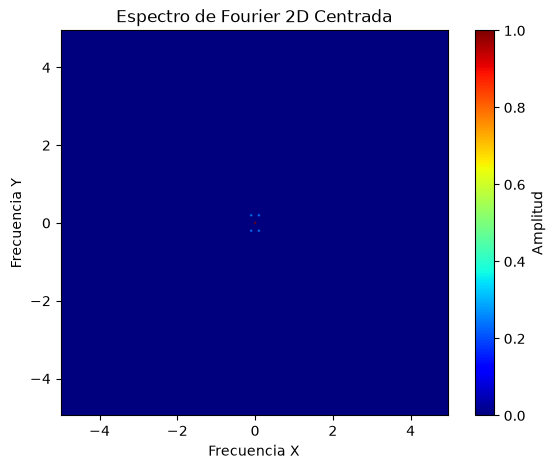

In [155]:
plt.figure(figsize=(7, 5))
plt.imshow(amplitud_normalizada, extent=[freq_x[0], freq_x[-1], freq_y[0], freq_y[-1]], 
           origin="lower", cmap="jet")
plt.colorbar(label="Amplitud")
plt.title("Espectro de Fourier 2D Centrada")
plt.xlabel("Frecuencia X")
plt.ylabel("Frecuencia Y")
plt.ylim(-4.95,4.95)

plt.show()

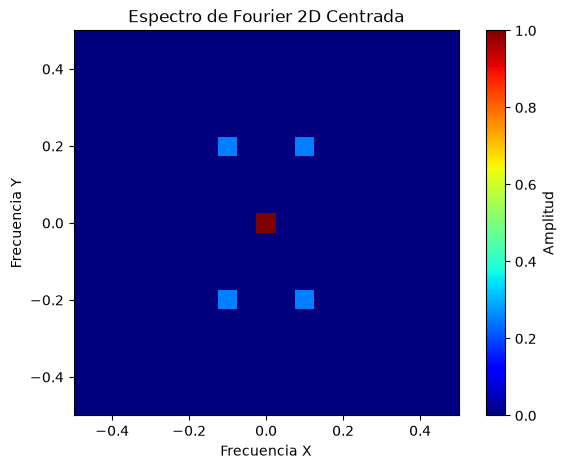

In [156]:
plt.figure(figsize=(7, 5))
plt.imshow(amplitud_normalizada, extent=[freq_x[0], freq_x[-1], freq_y[0], freq_y[-1]], 
           origin="lower", cmap="jet")
plt.colorbar(label="Amplitud")
plt.title("Espectro de Fourier 2D Centrada")
plt.xlabel("Frecuencia X")
plt.ylabel("Frecuencia Y")
plt.xlim(-0.5, 0.5)
plt.ylim(-0.5, 0.5)

plt.show()

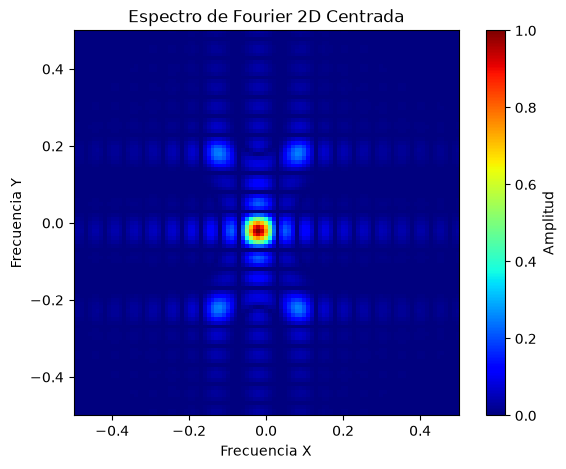

In [144]:
Z_fourier_continuo   = fft2(Z, s=(1000, 1000)) # 1000 pixeles x 1000 pixeles = 1 millon de  pixeles
Z_fourier_continuo_centrado = fftshift(Z_fourier_continuo)
amplitud_normalizada_continua = np.abs(Z_fourier_continuo_centrado) / (200 * 200)
plt.figure(figsize=(7, 5))
plt.imshow(amplitud_normalizada_continua, extent=[freq_x[0], freq_x[-1], freq_y[0], freq_y[-1]], 
           origin="lower", cmap="jet")
plt.colorbar(label="Amplitud")
plt.title("Espectro de Fourier 2D Centrada")
plt.xlabel("Frecuencia X")
plt.ylabel("Frecuencia Y")
plt.xlim(-0.5, 0.5)
plt.ylim(-0.5, 0.5)
plt.show()

### 2. Used the rutine created in class `FT(x,y)`. Modify it and do the FT to the signal. Do you get the same results?


In [ ]:
def FT2D(image_data, x_range, y_range):
    ''' Integrar la Transformada de Fourier 2D de una señal f(x, y) en rangos de frecuencia wx y wy '''

    wx = np.linspace(-0.5, 0.5, 100)
    wy = np.linspace(-0.5, 0.5, 100)
    # En total serian 10000 pixeles
    resultados = []

    for wxi in wx:
        for wyi in wy:
            
            # Núcleo de Fourier 2D: exp(-j * (wxi * x + wyi * y))
            integral_real, _ = integrate.dblquad(
                lambda y, x, wxi=wxi, wyi=wyi: image_data(x, y) * np.cos(2 * np.pi * (wxi * x + wyi * y)),
                x_range[0], x_range[1],
                lambda x: y_range[0], lambda x: y_range[1]
            )
            
            integral_imag, _ = integrate.dblquad(
                lambda y, x, wxi=wxi, wyi=wyi: image_data(x, y) * (-np.sin(2 * np.pi * (wxi * x + wyi * y))),
                x_range[0], x_range[1],
                lambda x: y_range[0], lambda x: y_range[1]
            )
            
            ARew = integral_real
            AIMw = integral_imag
            
            AMP = np.sqrt(ARew**2 + AIMw**2)
            ANG = np.arctan2(AIMw, ARew)
            
            resultados.append([wxi, wyi, ARew, AIMw, AMP, ANG])
            
    # 3. Crear el DataFrame con los resultados 2D
    df = pd.DataFrame(resultados, columns=['wx', 'wy', 'RetW', 'ImtW', 'AMP', 'ANG'])
    return df

In [130]:
rango_x = [0, 20]
rango_y = [0, 20]

df_resultados = FT2D(imagen, rango_x, rango_y)

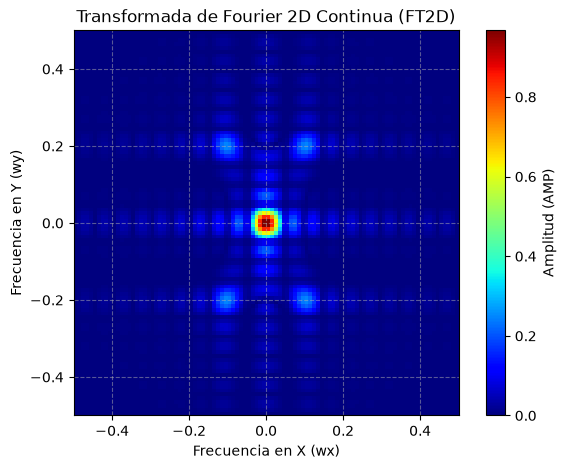

In [146]:
wx_vals = df_resultados['wx'].unique()
wy_vals = df_resultados['wy'].unique()

matriz_amp = df_resultados.pivot(index='wy', columns='wx', values='AMP').values
ancho_x = rango_x[1] - rango_x[0]
alto_y = rango_y[1] - rango_y[0]
area_total = ancho_x * alto_y

matriz_amp = matriz_amp / area_total

plt.figure(figsize=(7, 5))
plt.imshow(matriz_amp, 
           extent=[wx_vals[0], wx_vals[-1], wy_vals[0], wy_vals[-1]], 
           origin='lower', 
           cmap='jet')

plt.colorbar(label='Amplitud (AMP)')
plt.title('Transformada de Fourier 2D Continua (FT2D)')
plt.xlabel('Frecuencia en X (wx)')
plt.ylabel('Frecuencia en Y (wy)')

plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

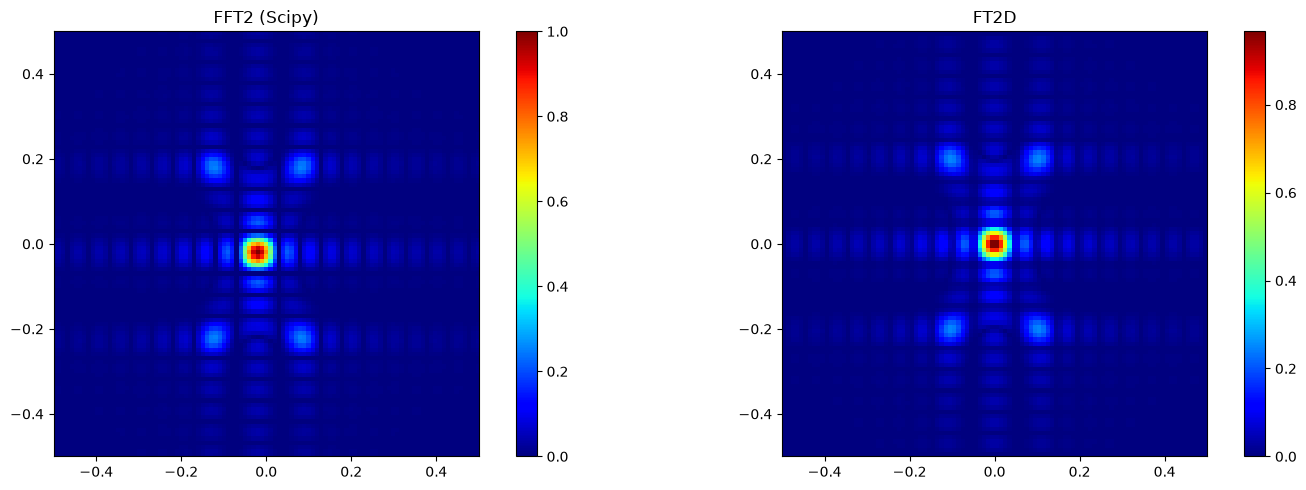

In [148]:
fig, ax = plt.subplots(1,2, figsize=(15,5))

ax[0].set_title("FFT2 (Scipy)")
ax[0].set_xlim(-0.5,0.5)
ax[0].set_ylim(-0.5,0.5)
im = ax[0].imshow(amplitud_normalizada_continua, extent=[freq_x[0], freq_x[-1], freq_y[0], freq_y[-1]], 
           origin="lower", cmap="jet")
fig.colorbar(im, ax=ax[0])

ax[1].set_title("FT2D")
im2 = ax[1].imshow(matriz_amp, extent=[wx_vals[0], wx_vals[-1], wy_vals[0], wy_vals[-1]], 
           origin='lower', 
           cmap='jet')

fig.colorbar(im2, ax=ax[1])

plt.tight_layout()

La razon por la que con 200 x 200 pixeles dan recuadros y con 1000 x 1000 ya si se forma el lobulo es por que fft2 lo hice para todo el rango de x y y por tanto solo se llega a calcular los puntos de amplitud de maxima (los rectangulos) y se pierde toda la informacion intermedio por la muestra que se hizo, cuando se aumenta ahora si se tiene resolucion suficiente para calcular otros pixeles donde la amplitud no es maxima y se logra ver la degradación de la señal.

En el caso de la función modificada FT2D ocurre es que por un lado solo se calcularon frecuencias donde ya sabia que estaban los picos en rangos muy cercanos, es por ello que aunque se forma una imagen 100 x 100 al tener un rango tan pequeño hay suficiente resolucioon para ver no solo los picos maximos si no tambien sus intermedios. Aun asi notese que ejecutar la funcion para estos rangos de frecuencias se tardo igual 17 min 36 sg debido a como funciona el metodo de integracion dblquad y a la gran cantidad de integrales que se deben realizar, en este caso, fueron 20000 integraciones, ya que son 10000 combinaciones de frecuencias que luego se utilizan para calcular dos integrales dobles (para seno y coseno).

### 3. Do the inverse FFT and reconstruc the original imagene. <br> Do you get a similar result? Compare the original and the reconstructed signal.

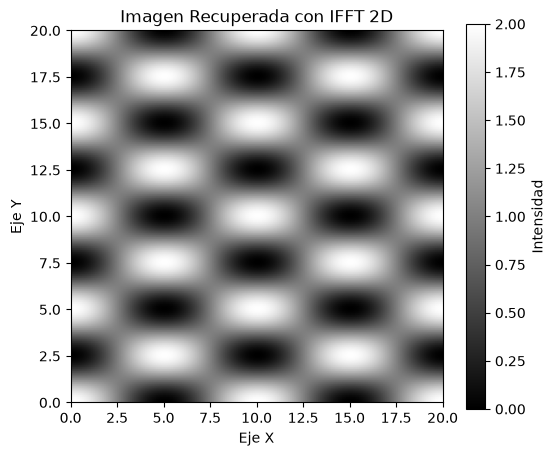

In [157]:
Z_fourier_sin_centrar = ifftshift(Z_fourier_centrado)
Z_recuperada_compleja = ifft2(Z_fourier_sin_centrar)
Z_recuperada = np.real(Z_recuperada_compleja) # Solo números reales conforma la imagen

plt.figure(figsize=(6, 5))
plt.imshow(Z_recuperada, extent=[0, 20, 0, 20], origin='lower', cmap='gray')
plt.colorbar(label='Intensidad')
plt.title('Imagen Recuperada con IFFT 2D')
plt.xlabel('Eje X')
plt.ylabel('Eje Y')
plt.show()

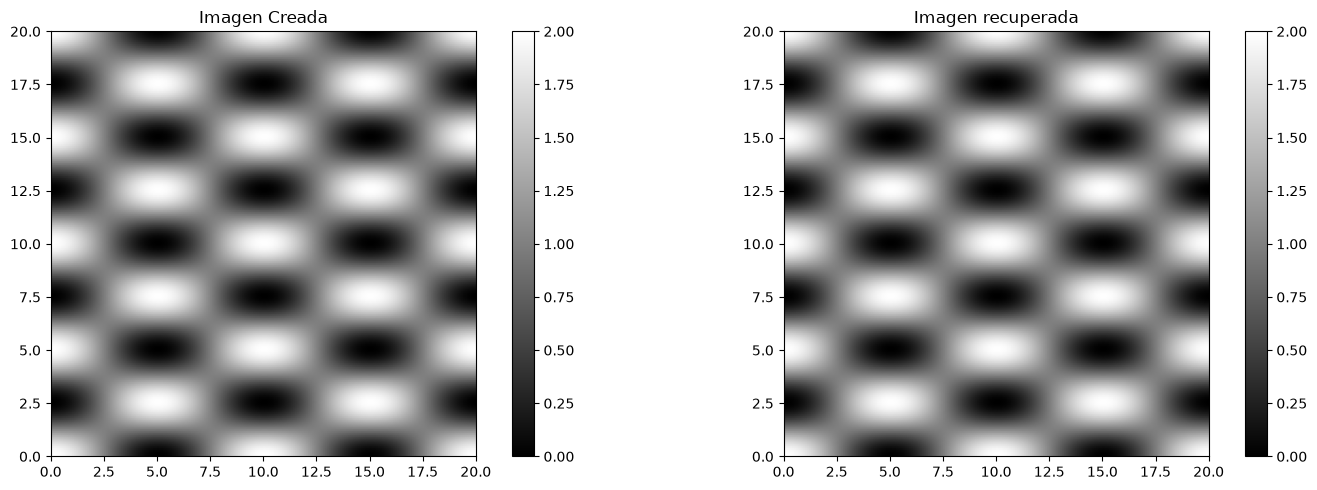

In [158]:
fig, ax = plt.subplots(1,2, figsize=(15,5))

ax[0].set_title("Imagen Creada")
im = ax[0].imshow(Z, extent=[0, 20, 0, 20], origin="lower", cmap="gray")
fig.colorbar(im, ax=ax[0])

ax[1].set_title("Imagen recuperada")
im2 = ax[1].imshow(Z_recuperada, extent=[0, 20, 0, 20], origin='lower', cmap='gray')
fig.colorbar(im2, ax=ax[1])

plt.tight_layout()

In [159]:
diferencia = Z - Z_recuperada

error_maximo = np.max(np.abs(diferencia))
print("El error real entre las dos imágenes es de:", error_maximo)

El error real entre las dos imágenes es de: 1.3322676295501878e-15


Se obtuvo la misma imagen es decir el proceso de descomponer una imagen en las frecuencias que la componen y luego reconstruirla con la información obtenida nos lleva a la recreación de la imagen original.